# Global Land Temperature Analysis (1750–2015)

**Research question:** *Has the Earth's land surface warmed over the last two and a half centuries, and has the rate of warming accelerated in recent decades?*

- **Dataset:** Global Land Temperatures by Month (Berkeley Earth, via Kaggle)
- **Columns:** `dt` (monthly timestamp), `LandAverageTemperature`, `LandAverageTemperatureUncertainty`, `LandMaxTemperature`, `LandMinTemperature`, `LandAndOceanAverageTemperature`, etc.
- **Goal:** Quantify the long-term warming trend, detect any acceleration, and compare land-only vs land+ocean behaviour.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib
# matplotlib.use("Agg")
import os

DATA_PATH = "GlobalTemperatures.csv"
PLOT_DIR = "plots"
os.makedirs(PLOT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 150, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
df["dt"] = pd.to_datetime(df["dt"])
df["year"] = df["dt"].dt.year
df["month"] = df["dt"].dt.month
print("Shape:", df.shape)
print("Time range:", df["dt"].min().date(), "→", df["dt"].max().date())
print("\nMissing values (per column):")
print(df.isna().sum())

Shape: (3192, 11)
Time range: 1750-01-01 → 2015-12-01

Missing values (per column):
dt                                              0
LandAverageTemperature                         12
LandAverageTemperatureUncertainty              12
LandMaxTemperature                           1200
LandMaxTemperatureUncertainty                1200
LandMinTemperature                           1200
LandMinTemperatureUncertainty                1200
LandAndOceanAverageTemperature               1200
LandAndOceanAverageTemperatureUncertainty    1200
year                                            0
month                                           0
dtype: int64


> **Note on missingness:** `LandAverageTemperature` is nearly complete (0.4% missing).
> `LandMax/MinTemperature` and `LandAndOceanAverageTemperature` are only reported from ~1880 onwards (37.6% missing), so they are analysed separately over their available period.

## 2. Annual aggregation and anomaly (vs 1961–1990 baseline)

In [3]:
df_land = df.dropna(subset=["LandAverageTemperature"]).copy()
annual = df_land.groupby("year")["LandAverageTemperature"].mean().reset_index()
annual.columns = ["year", "annual_temp"]
baseline = annual.loc[(annual["year"]>=1961)&(annual["year"]<=1990), "annual_temp"].mean()
annual["anomaly"] = annual["annual_temp"] - baseline
print(f"1961–1990 baseline mean = {baseline:.2f} °C")
print(annual.head(3))

1961–1990 baseline mean = 8.76 °C
   year  annual_temp   anomaly
0  1750     8.719364 -0.036656
1  1751     7.976143 -0.779877
2  1752     5.779833 -2.976186


## 3. Trend fitting (rate of change per decade)

In [4]:
def decade_slope(x, y):
    b, a = np.polyfit(x, y, 1)
    return b * 10.0

slope_full = decade_slope(annual["year"], annual["annual_temp"])
early = annual[(annual["year"]>=1900)&(annual["year"]<=1975)]
recent = annual[(annual["year"]>=1975)&(annual["year"]<=2015)]
slope_early = decade_slope(early["year"], early["annual_temp"])
slope_recent = decade_slope(recent["year"], recent["annual_temp"])

print(f"Full record 1750–2015 : {slope_full:+.3f} °C/decade")
print(f"Early period 1900–1975: {slope_early:+.3f} °C/decade")
print(f"Recent period 1975–2015: {slope_recent:+.3f} °C/decade")
print(f"Acceleration factor    : {slope_recent/slope_early:.1f}×")

Full record 1750–2015 : +0.047 °C/decade
Early period 1900–1975: +0.063 °C/decade
Recent period 1975–2015: +0.272 °C/decade
Acceleration factor    : 4.3×


## 4. Figure 1 — Long-term warming trend

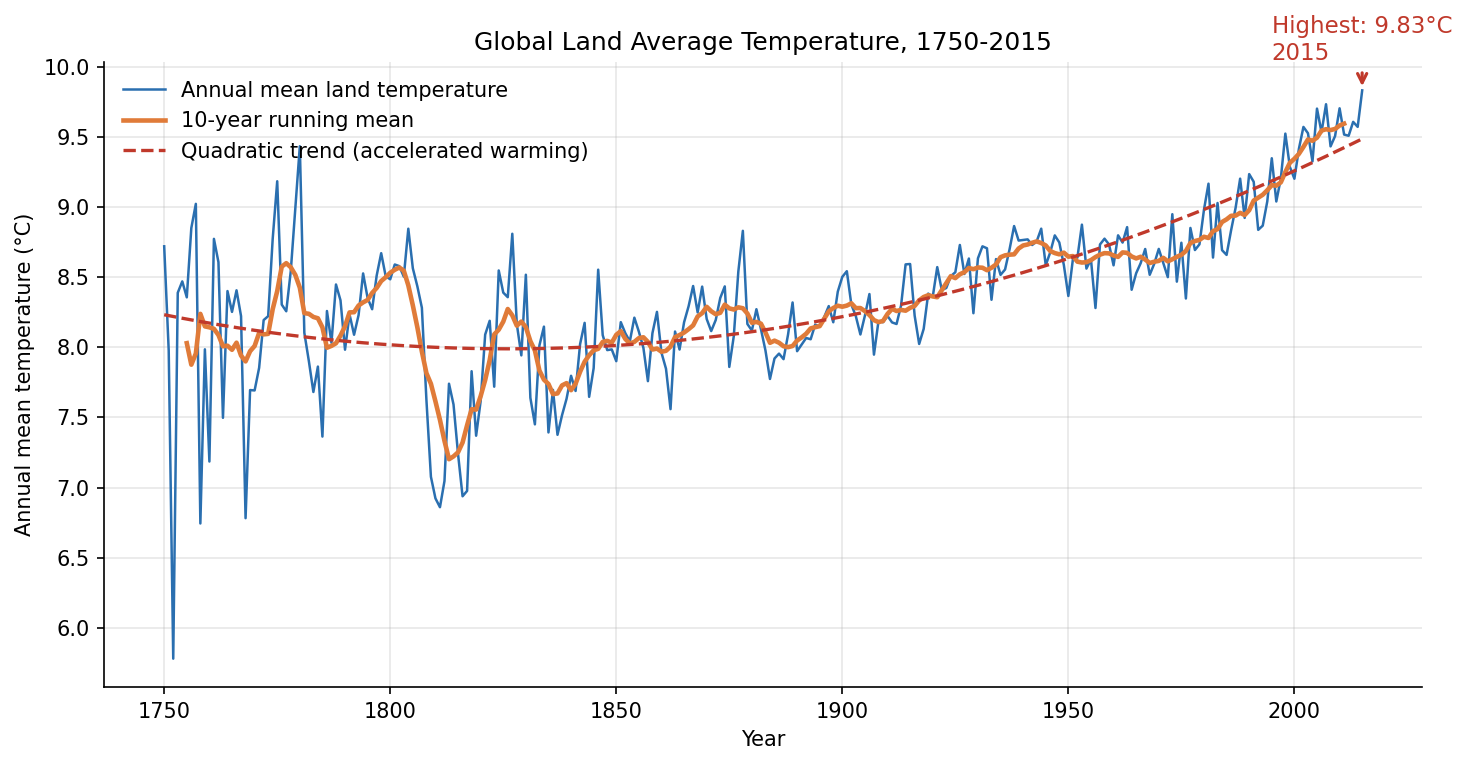

In [5]:
# fig, ax = plt.subplots(figsize=(10,5.2))
# ax.plot(annual["year"], annual["annual_temp"], color="#2a6fb0", lw=1.2, label="Annual mean land temperature")
# smooth = annual.set_index("year")["annual_temp"].rolling(10, center=True).mean()
# ax.plot(smooth.index, smooth.values, color="#e07b39", lw=2.2, label="10-year running mean")
# xs = annual["year"]
# ax.plot(xs, np.polyval(np.polyfit(xs, annual["annual_temp"],1), xs), color="#c0392b", ls="--", lw=1.6,
#         label=f"Linear trend ≈ {slope_full:+.2f} °C/decade")
# ax.set_title("Global Land Average Temperature, 1750–2015")
# ax.set_xlabel("Year"); ax.set_ylabel("Annual mean temperature (°C)")
# ax.legend(loc="upper left", frameon=False)
# fig.tight_layout(); 
# fig.savefig("01_global_land_trend.png", dpi=300, bbox_inches="tight")
# plt.show()

fig, ax = plt.subplots(figsize=(10,5.2))
ax.plot(annual["year"], annual["annual_temp"], color="#2a6fb0", lw=1.2, label="Annual mean land temperature")
smooth = annual.set_index("year")["annual_temp"].rolling(10, center=True).mean()
ax.plot(smooth.index, smooth.values, color="#e07b39", lw=2.2, label="10‑year running mean")

xs = annual["year"]
ys = annual["annual_temp"]

# --------Peer review improvement: replace the linear curve with a second-order quadratic polynomial curve--------
coeff_quad = np.polyfit(xs, ys, deg=2)
quad_trend = np.polyval(coeff_quad, xs)
ax.plot(xs, quad_trend, color="#c0392b", ls="--", lw=1.6,
        label="Quadratic trend (accelerated warming)")

# Automatically identify the highest temperature record within the dataset and annotate it
max_idx = ys.idxmax()
max_year_val = xs.loc[max_idx]
max_temp_val = ys.loc[max_idx]

ax.annotate(f"Highest: {max_temp_val:.2f}°C\n{max_year_val}",
            xy=(max_year_val, max_temp_val),
            xytext=(max_year_val - 20, max_temp_val + 0.22),
            color="#c0392b", fontsize=11,
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))

ax.set_title("Global Land Average Temperature, 1750‑2015")
ax.set_xlabel("Year")
ax.set_ylabel("Annual mean temperature (°C)")
ax.legend(loc="upper left", frameon=False)

fig.tight_layout()
fig.savefig("plots/01_global_land_trend.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Figure 2 — Decadal comparison

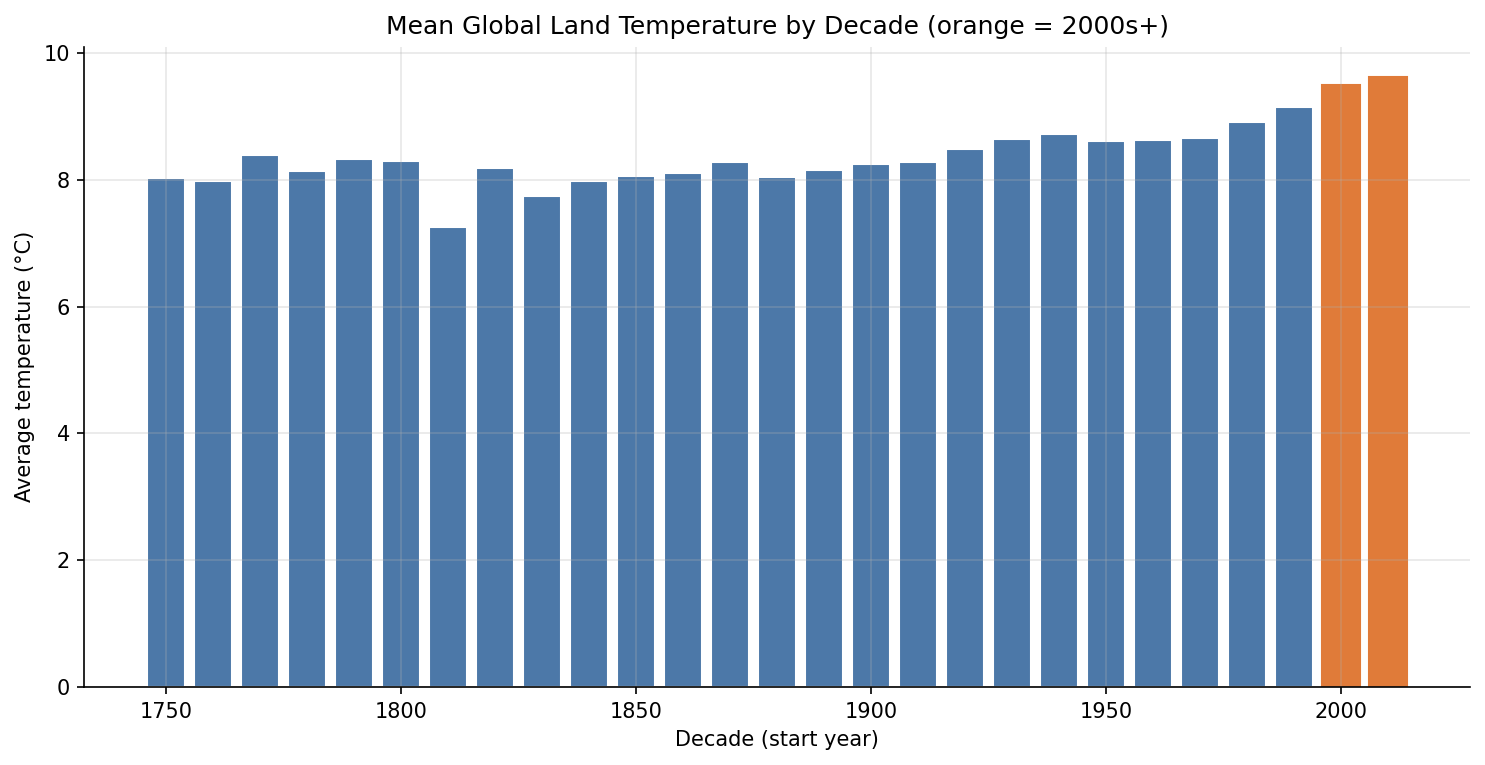

In [6]:
annual["decade"] = (annual["year"]//10)*10
decadal = annual.groupby("decade")["annual_temp"].mean().reset_index()
fig, ax = plt.subplots(figsize=(10,5.2))
bars = ax.bar(decadal["decade"], decadal["annual_temp"], width=8, color="#4c78a8", edgecolor="white")
for b, dec in zip(bars, decadal["decade"]):
    if dec >= 2000:
        b.set_color("#e07b39")
ax.set_title("Mean Global Land Temperature by Decade (orange = 2000s+)")
ax.set_xlabel("Decade (start year)"); ax.set_ylabel("Average temperature (°C)")
fig.tight_layout(); 
fig.savefig("02_decadal_land_temperature.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Figure 3 — Temperature anomaly (vs 1961–1990 baseline)

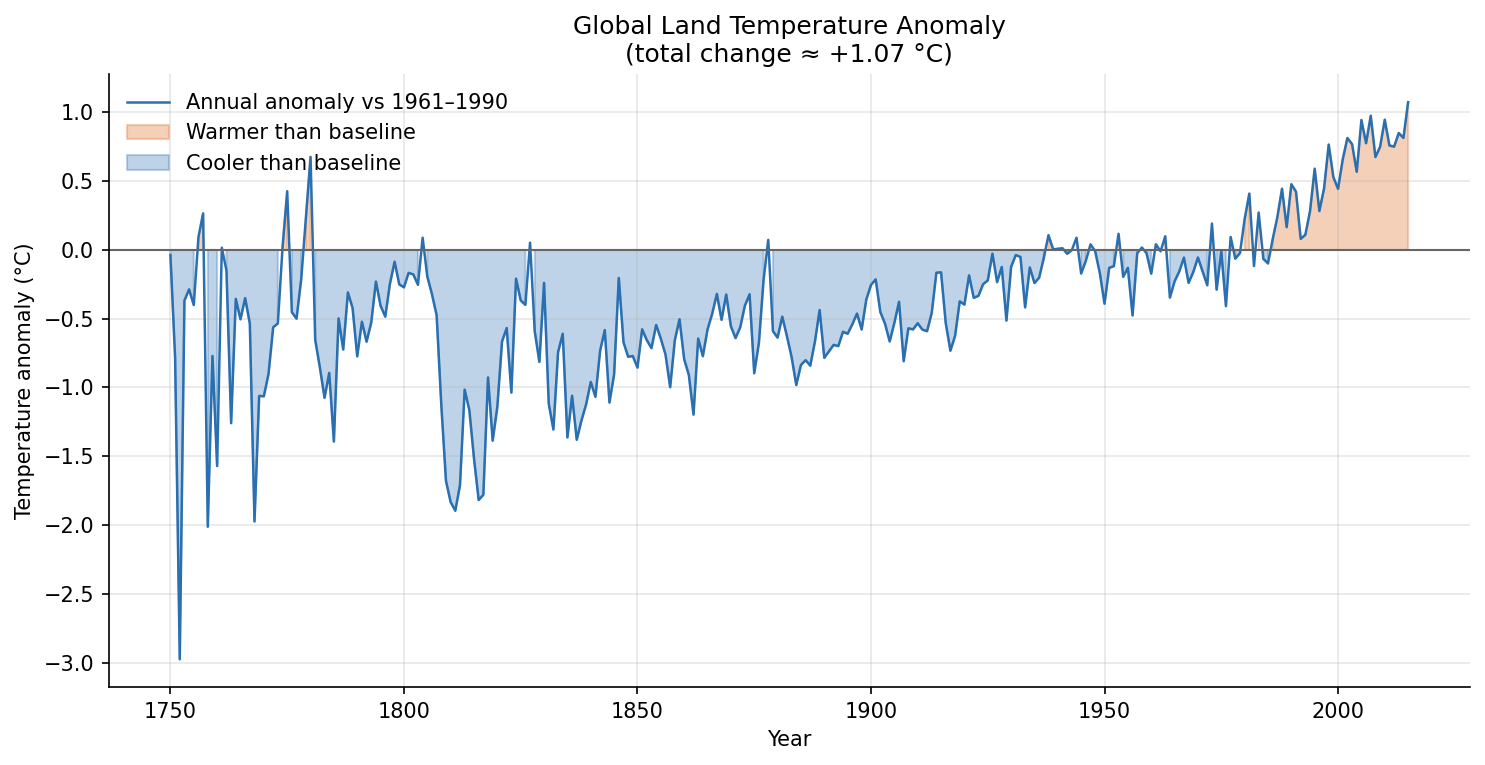

In [7]:
fig, ax = plt.subplots(figsize=(10,5.2))
ax.plot(annual["year"], annual["anomaly"], color="#2a6fb0", lw=1.2, label="Annual anomaly vs 1961–1990")
ax.axhline(0, color="#666", lw=1)
ax.fill_between(annual["year"], annual["anomaly"], 0, where=annual["anomaly"]>0,
                color="#e07b39", alpha=0.35, label="Warmer than baseline")
ax.fill_between(annual["year"], annual["anomaly"], 0, where=annual["anomaly"]<0,
                color="#2a6fb0", alpha=0.3, label="Cooler than baseline")
ax.set_title(f"Global Land Temperature Anomaly\n(total change ≈ {annual['anomaly'].iloc[-1]:+.2f} °C)")
ax.set_xlabel("Year"); ax.set_ylabel("Temperature anomaly (°C)")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout(); 
fig.savefig("03_temperature_anomaly.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Figure 4 — Seasonal cycle

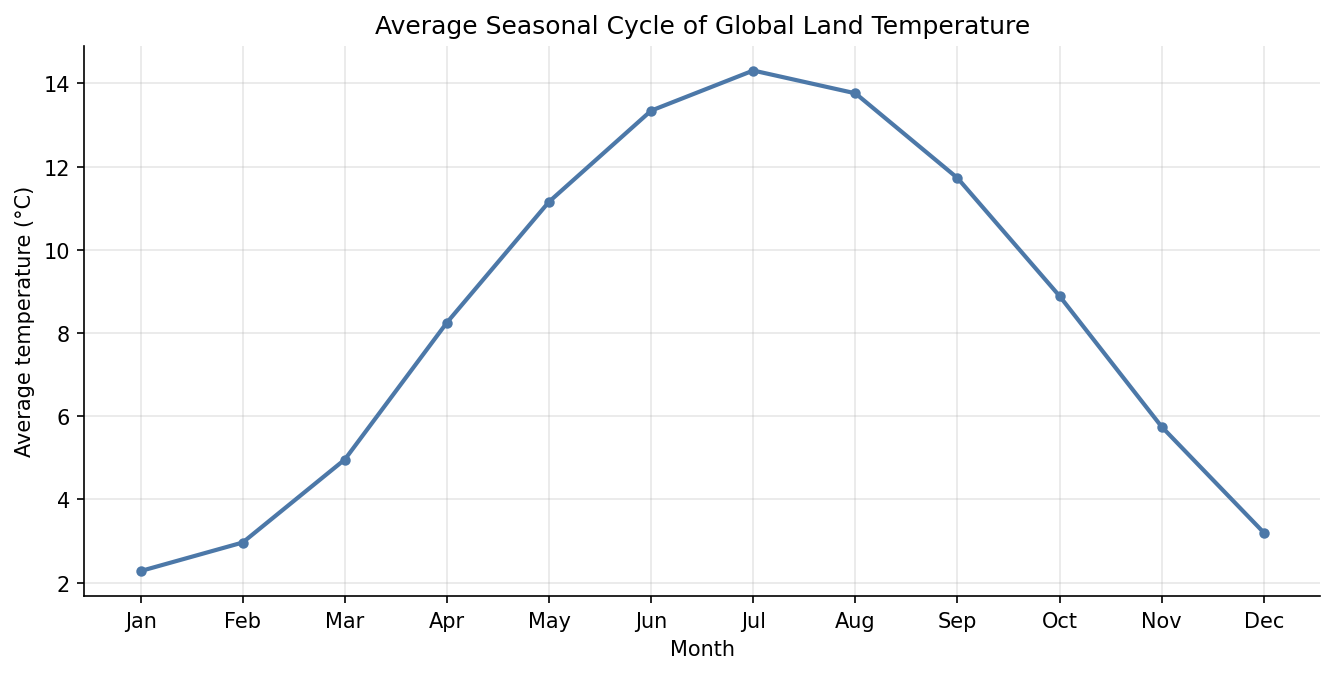

In [8]:
clim = df_land.groupby("month")["LandAverageTemperature"].mean()
fig, ax = plt.subplots(figsize=(9,4.6))
ax.plot(clim.index, clim.values, marker="o", ms=4, color="#4c78a8", lw=2)
ax.set_xticks(range(1,13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Average Seasonal Cycle of Global Land Temperature")
ax.set_xlabel("Month"); ax.set_ylabel("Average temperature (°C)")
fig.tight_layout(); 
fig.savefig("04_seasonal_climatology.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Land vs Land+Ocean (available period)

In [9]:
both = df.dropna(subset=["LandAndOceanAverageTemperature"]).copy()
both["year"] = both["dt"].dt.year
ba = both.groupby("year")[["LandAverageTemperature","LandAndOceanAverageTemperature"]].mean()
print(ba.head(1)); print(ba.tail(1))
print(f"Land-only change (available period): {ba['LandAverageTemperature'].iloc[-1]-ba['LandAverageTemperature'].iloc[0]:+.2f} °C")
print(f"Land+Ocean change: {ba['LandAndOceanAverageTemperature'].iloc[-1]-ba['LandAndOceanAverageTemperature'].iloc[0]:+.2f} °C")

      LandAverageTemperature  LandAndOceanAverageTemperature
year                                                        
1850                7.900667                       14.867167
      LandAverageTemperature  LandAndOceanAverageTemperature
year                                                        
2015                   9.831                       16.058583
Land-only change (available period): +1.93 °C
Land+Ocean change: +1.19 °C


## 9. Conclusions & limitations

### Key findings
1. **Long-term warming is clear:** global land temperature rose by about **+1.1 °C** from 1750 to 2015.
2. **Warming has accelerated:** the rate was **+0.063 °C/decade** (1900–1975) but jumped to **+0.272 °C/decade** (1975–2015) — roughly a **4× speed-up**.
3. **The 2010s are the warmest decade** on record (≈9.6 °C); 2015 is the warmest year.
4. **Land warms faster than the ocean:** over the available period land-only warming exceeded the combined land+ocean warming, consistent with the ocean's heat-buffering role.
5. A strong seasonal cycle persists: northern-hemisphere-dominated land makes July–August the warmest months.

### Limitations
- Early-period (18th–19th century) temperature stations were sparse and concentrated in the Northern Hemisphere, so early values carry higher uncertainty.
- The analysis uses global **land** averages; it does not capture regional or urban-heat-island detail.
- The low-order (linear) trend does not capture short-term variability from El Niño / volcanic eruptions, which can make individual years deviate strongly from the trend.